In [45]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json
import csv
plt.style.use('bmh')

In [46]:
model = "Gr00t"
dataroots = [
    'random_gr00t-4200' + '/',
    'random_gr00t-5000' + '/',
    'random_gr00t-6000' + '/',
    'approach_random_additional_0distr_gr00t_seed-4201_gr00t_07-11_00-16' + '/',
    'approach_random_additional_4distr_gr00t_seed-4201_gr00t_07-10_14-07' + '/',
]
datapaths = [[dataroot + 'run-' + str(x) + '/'  for x in range(3)] for dataroot in dataroots]

In [47]:
datapaths

[['random_gr00t-4200/run-0/',
  'random_gr00t-4200/run-1/',
  'random_gr00t-4200/run-2/'],
 ['random_gr00t-5000/run-0/',
  'random_gr00t-5000/run-1/',
  'random_gr00t-5000/run-2/'],
 ['random_gr00t-6000/run-0/',
  'random_gr00t-6000/run-1/',
  'random_gr00t-6000/run-2/'],
 ['approach_random_additional_0distr_gr00t_seed-4201_gr00t_07-11_00-16/run-0/',
  'approach_random_additional_0distr_gr00t_seed-4201_gr00t_07-11_00-16/run-1/',
  'approach_random_additional_0distr_gr00t_seed-4201_gr00t_07-11_00-16/run-2/'],
 ['approach_random_additional_4distr_gr00t_seed-4201_gr00t_07-10_14-07/run-0/',
  'approach_random_additional_4distr_gr00t_seed-4201_gr00t_07-10_14-07/run-1/',
  'approach_random_additional_4distr_gr00t_seed-4201_gr00t_07-10_14-07/run-2/']]

## Loading dataframe

In [48]:
def str_or_bool(x):
    res = x
    if res:
        if isinstance(res, str):
            res = True if res == 'true' else False
    return res

In [49]:
dfs = []
[dfs.append([]) for _ in range(len(dataroots))]
[dfs[i].append([]) for i in range(len(dataroots)) for _ in range(3)]
for d_idx, _ in enumerate(dataroots):
    for r_idx in range(3):
        nb = []
        coordinates = []
        [coordinates.append([]) for _ in range(0,12)]
        distractors = []
        prompts = []
        flags = []
        folders = sorted([int(f) for f in os.listdir(datapaths[d_idx][r_idx])])
        options = []
        paths = []

        for datapoint in folders:
            path = os.path.join(datapaths[d_idx][r_idx], str(datapoint) + '/') # default path
            paths.append(path)
            nb.append(datapoint)
            with open(path + 'distractor.csv', 'r') as f:
                reader = csv.reader(f, delimiter=',', quotechar='"')
                for row in reader:
                    values = [v.replace('[', '').replace(']', '').replace(' ', '') for v in row]
                    distr = sum([int(float(v)) for v in values])
                    distractors.append(distr)

            with open(path + 'prompt.txt', 'r') as f:
                lines = f.readlines()
                for line in lines:
                    prompts.append(line)
            with open(path + 'flags.json', 'r') as f:
                data = json.load(f)
                flags.append({key: str_or_bool(value) for key, value in data.items()})
            with open(path + 'options.json', 'r') as f:
                data = json.load(f)
                options.append(data)
                ids = data["model_ids"]
                items = data["obj_init_options"]
                for idx in range(0,len(coordinates),2):
                    if idx//2 < len(ids):
                        coordinates[idx].append(items[ids[idx//2]]["init_xy"][0])
                        coordinates[idx+1].append(items[ids[idx//2]]["init_xy"][1])
                    else:
                        coordinates[idx].append(99)
                        coordinates[idx+1].append(99)

        df = pd.DataFrame(nb, columns=['vid_nb'])

        for idx in range(0, len(coordinates), 2):
            df['x' + str(idx//2+1)] = coordinates[idx]
            df['y' + str(idx//2+1)] = coordinates[idx+1]

        df['distractor'] = distractors
        df['prompt'] = prompts
        df['flags'] = flags
        df['options'] = options
        df['paths'] = paths
        df = df.set_index("vid_nb")
        dfs[d_idx][r_idx] = df

In [50]:
metric_acronyms = {
    'Token_based_token_prob':"TB_TP",
    'Token_based_pcs':"TB_PCS",
    'Token_based_deepgini':"TB_D",
    'Token_based_entropy':"TB_E",
    
    'position_instability':"A_PI",
    'velocity_instability':"A_VI",
    'acceleration_instability':"A_AI",

    'TCP_position_instability':"TCP_PI",
    'TCP_velocity_instability':"TCP_VI",
    'TCP_acceleration_instability':"TCP_AI",

    'Trajectory_Instability_Gradients':"TI",
    'Optimal_Trajectory':"OT",
    'Execution_Variability':"EV",

    # added mapping unique to this notebook
    'actions':"actions",
    'tcp_poses':"tcp_poses",
    'gripper_distances': 'gripper_distances',
    'obj_distances': 'obj_distances',
    'episode_coords': 'episode_coords',
    'frame0_coords': 'frame0_coords',
    'shapes': 'shapes,'
}

In [51]:
import glob

for d_idx in range(len(dataroots)):
    for r_idx in range(3):
        columns = dict()
        folders = sorted([int(f) for f in os.listdir(datapaths[d_idx][r_idx])])
        for key in metric_acronyms:
            acronym = metric_acronyms[key]
            columns[acronym] = []

        for datapoint in folders:
            path = os.path.join(datapaths[d_idx][r_idx], str(datapoint) + '/')
            filelist = glob.glob(path + "*.json")
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('exec_time')] # excluding exec_time related files
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('log')] # excluding log files as it needs specific processing
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('coordinates')] # excluding coordinates already processed
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('score')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('prompt')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('options')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('flags')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('Token')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('TCP')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('position_instability')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('velocity_instability')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('acceleration_instability')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('Trajectory_Instability_Gradients')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('Optimal_Trajectory')] 
            filelist = [f for f in filelist if not f.split('/')[-1].startswith('Execution_Variability')] 

            for file in filelist:
                metric_name = file.split('/')[-1].split('.')[0]
                acronym = metric_acronyms[metric_name]
                
                with open(file, 'r') as f:
                    data = pd.DataFrame(json.load(f))
                    columns[acronym].append(data)

        for key in columns:
            if len(columns[key]) != 0:
                dfs[d_idx][r_idx][key] = columns[key]

In [52]:
for d_idx in range(len(dataroots)):
    for r_idx in range(3):
        episode_success = []
        earliest_success = []
        folders = sorted([int(f) for f in os.listdir(datapaths[d_idx][r_idx])])
        for datapoint in folders:
            path = os.path.join(datapaths[d_idx][r_idx], str(datapoint) + '/')
            with open(path + 'log.json', 'r') as f:
                data = json.load(f)
                episode_success.append(True if data[list(data)[-1]]['correct_on_target'] == 'true' else False)
                #episode_success.append(True if data[list(data)[-1]]['success'] == 'true' else False)
                found = False
                for idx in range(len(list(data))):
                    if data[list(data)[-1]]['correct_on_target'] == 'false':
                        break
                    if data[list(data)[idx]]['correct_on_target'] == 'true':
                    #if data[list(data)[idx]]['success'] == 'true':
                        earliest_success.append(idx)
                        found = True
                        break
                if not found:
                    earliest_success.append(120)

        dfs[d_idx][r_idx]['success'] = episode_success
        dfs[d_idx][r_idx]['earliest_success'] = earliest_success

In [53]:
dfs[0][0].loc[(dfs[0][0]["success"] == False) & (dfs[0][0]["earliest_success"] != -1)]

,x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,...,paths,actions,tcp_poses,gripper_distances,obj_distances,episode_coords,frame0_coords,"shapes,",success,earliest_success
vid_nb,,,,,,,,,,,,,,,,,,,,,
0,-0.078,0.15,-0.174,-0.15,-0.270,0.15,-0.174,0.0,-0.078,-0.2,...,random_gr00t-4200/run-0/0/,worl...,0 1 2 3 ...,0 0 0.488133 1 0.475405 2 ...,0 0 0.316697 1 0.316697 2 ...,...,0 1 2 0 -0.075252 0...,0 0 3 1 0,False,120
1,-0.126,-0.10,-0.078,0.00,-0.174,0.15,99.000,99.0,99.000,99.0,...,random_gr00t-4200/run-0/1/,worl...,0 1 2 3 ...,0 0 0.280656 1 0.266429 2 ...,0 0 0.109150 1 0.109150 2 ...,bridge_carrot_generated_...,0 1 2 0 -0.12530...,0 0 4 1 0,False,120
3,-0.270,-0.20,-0.078,0.00,-0.222,-0.10,-0.174,-0.2,99.000,99.0,...,random_gr00t-4200/run-0/3/,worl...,0 1 2 3 ...,0 0 0.549636 1 0.537290 2 ...,0 0 0.27193 1 0.27193 2 0....,...,0 1 2 0 -0.261438 -0...,0 0 3 1 1,False,120
4,-0.126,-0.20,-0.222,-0.20,-0.174,0.10,-0.126,-0.1,99.000,99.0,...,random_gr00t-4200/run-0/4/,worl...,0 1 2 3 ...,0 0 0.357840 1 0.361493 2 ...,0 0 0.097124 1 0.097124 2 ...,...,0 1 2 0 -0.125998 -0...,0 0 2 1 0,False,120
7,-0.078,0.15,-0.270,0.15,-0.174,0.10,99.000,99.0,99.000,99.0,...,random_gr00t-4200/run-0/7/,worl...,0 1 2 3 ...,0 0 0.364101 1 0.355306 2 ...,0 0 0.192454 1 0.192454 2 ...,yellow_...,0 1 2 0 -0.077972 0...,0 0 1 1 0,False,120
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,-0.174,0.05,-0.270,-0.15,99.000,99.00,99.000,99.0,99.000,99.0,...,random_gr00t-4200/run-0/594/,worl...,0 1 2 3 ...,0 0 0.327827 1 0.320722 2 ...,0 0 0.223089 1 0.223089 2 ...,...,0 1 2 0 -0.174115 0...,0 0 0 1 0,False,120
595,-0.222,0.00,-0.270,0.10,-0.270,-0.15,99.000,99.0,99.000,99.0,...,random_gr00t-4200/run-0/595/,worl...,0 1 2 3 ...,0 0 0.246855 1 0.239086 2 ...,0 0 0.109841 1 0.109841 2 ...,...,0 1 2 0 -0.221997 -0...,0 0 2 1 1,False,120
596,-0.174,0.00,-0.078,-0.20,-0.174,0.10,-0.078,0.1,99.000,99.0,...,random_gr00t-4200/run-0/596/,worl...,0 1 2 3 ...,0 0 0.344915 1 0.336279 2 ...,0 0 0.222009 1 0.222009 2 ...,yellow_...,0 1 2 0 -0.173972 -0...,0 0 1 1 0,False,120


In [54]:
dfs[0][0].drop(dfs[0][0].loc[dfs[0][0]["distractor"] == 1][50:].index)

,x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,...,paths,actions,tcp_poses,gripper_distances,obj_distances,episode_coords,frame0_coords,"shapes,",success,earliest_success
vid_nb,,,,,,,,,,,,,,,,,,,,,
0,-0.078,0.15,-0.174,-0.15,-0.270,0.15,-0.174,0.00,-0.078,-0.2,...,random_gr00t-4200/run-0/0/,worl...,0 1 2 3 ...,0 0 0.488133 1 0.475405 2 ...,0 0 0.316697 1 0.316697 2 ...,...,0 1 2 0 -0.075252 0...,0 0 3 1 0,False,120
1,-0.126,-0.10,-0.078,0.00,-0.174,0.15,99.000,99.00,99.000,99.0,...,random_gr00t-4200/run-0/1/,worl...,0 1 2 3 ...,0 0 0.280656 1 0.266429 2 ...,0 0 0.109150 1 0.109150 2 ...,bridge_carrot_generated_...,0 1 2 0 -0.12530...,0 0 4 1 0,False,120
2,-0.078,0.05,-0.270,0.00,-0.270,0.10,-0.270,-0.15,-0.126,-0.1,...,random_gr00t-4200/run-0/2/,worl...,0 1 2 3 ...,0 0 0.346470 1 0.337543 2 ...,0 0 0.208121 1 0.208121 2 ...,bridge_spoon_generated_...,0 1 2 0 -0.07684...,0 0 4 1 0,True,60
3,-0.270,-0.20,-0.078,0.00,-0.222,-0.10,-0.174,-0.20,99.000,99.0,...,random_gr00t-4200/run-0/3/,worl...,0 1 2 3 ...,0 0 0.549636 1 0.537290 2 ...,0 0 0.27193 1 0.27193 2 0....,...,0 1 2 0 -0.261438 -0...,0 0 3 1 1,False,120
4,-0.126,-0.20,-0.222,-0.20,-0.174,0.10,-0.126,-0.10,99.000,99.0,...,random_gr00t-4200/run-0/4/,worl...,0 1 2 3 ...,0 0 0.357840 1 0.361493 2 ...,0 0 0.097124 1 0.097124 2 ...,...,0 1 2 0 -0.125998 -0...,0 0 2 1 0,False,120
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
593,-0.174,-0.15,-0.270,0.10,-0.174,-0.05,-0.078,0.05,99.000,99.0,...,random_gr00t-4200/run-0/593/,worl...,0 1 2 3 ...,0 0 0.485534 1 0.480241 2 ...,0 0 0.268202 1 0.268202 2 ...,yellow_...,0 1 2 0 -0.173972 -0...,0 0 1 1 0,False,120
594,-0.174,0.05,-0.270,-0.15,99.000,99.00,99.000,99.00,99.000,99.0,...,random_gr00t-4200/run-0/594/,worl...,0 1 2 3 ...,0 0 0.327827 1 0.320722 2 ...,0 0 0.223089 1 0.223089 2 ...,...,0 1 2 0 -0.174115 0...,0 0 0 1 0,False,120
596,-0.174,0.00,-0.078,-0.20,-0.174,0.10,-0.078,0.10,99.000,99.0,...,random_gr00t-4200/run-0/596/,worl...,0 1 2 3 ...,0 0 0.344915 1 0.336279 2 ...,0 0 0.222009 1 0.222009 2 ...,yellow_...,0 1 2 0 -0.173972 -0...,0 0 1 1 0,False,120


In [55]:
filling_cpt_0 = 0
filling_cpt_4 = 0
distr_0 = dfs[3]
distr_4 = dfs[4]

missing = dfs[0][0].groupby("distractor").count().loc[0]["x1"]

for d_index in range(3):
    missing_0 = 50 - dfs[d_index][0].groupby("distractor").count().loc[0]["x1"]
    missing_4 = 50 - dfs[d_index][0].groupby("distractor").count().loc[4]["x1"]
    filling_cpt_0 += missing_0
    filling_cpt_4 += missing_4
    for r_index in range(3):
        dfs[d_index][r_index] = dfs[d_index][r_index].drop(dfs[d_index][r_index].loc[dfs[d_index][r_index]["distractor"] == 1][50:].index)
        dfs[d_index][r_index] = dfs[d_index][r_index].drop(dfs[d_index][r_index].loc[dfs[d_index][r_index]["distractor"] == 2][50:].index)
        dfs[d_index][r_index] = dfs[d_index][r_index].drop(dfs[d_index][r_index].loc[dfs[d_index][r_index]["distractor"] == 3][50:].index)

        to_add = distr_0[r_index].loc[filling_cpt_0:filling_cpt_0+missing_0-1]
        dfs[d_index][r_index]= pd.concat([dfs[d_index][r_index], to_add], ignore_index=True)
        to_add = distr_4[r_index].loc[filling_cpt_4:filling_cpt_4+missing_4-1]
        dfs[d_index][r_index]= pd.concat([dfs[d_index][r_index], to_add], ignore_index=True)

In [56]:
dfs[2][0].groupby("distractor").count()
#filling_cpt_0

,x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,...,paths,actions,tcp_poses,gripper_distances,obj_distances,episode_coords,frame0_coords,"shapes,",success,earliest_success
distractor,,,,,,,,,,,,,,,,,,,,,
0,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
1,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
2,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
3,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
4,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50


In [57]:
# IMPORTANT
dfs = dfs[:3]
len(dfs)

3

## Plotting - FULL

In [58]:
raw = dfs[0][0]['episode_coords'][0]['orange']
formatted = pd.DataFrame([[x,y,z] for x,y,z in raw], columns=['x','y','z'])

In [59]:
formatted

,x,y,z
0,-0.075252,0.150656,0.886969
1,-0.075252,0.150656,0.886969
2,-0.075252,0.150656,0.886969
3,-0.075252,0.150656,0.886969
4,-0.075252,0.150656,0.886969
...,...,...,...
115,-0.180149,0.102376,0.886955
116,-0.180149,0.102376,0.886955
117,-0.180149,0.102376,0.886955
118,-0.180149,0.102376,0.886955


(0.0, -0.35)

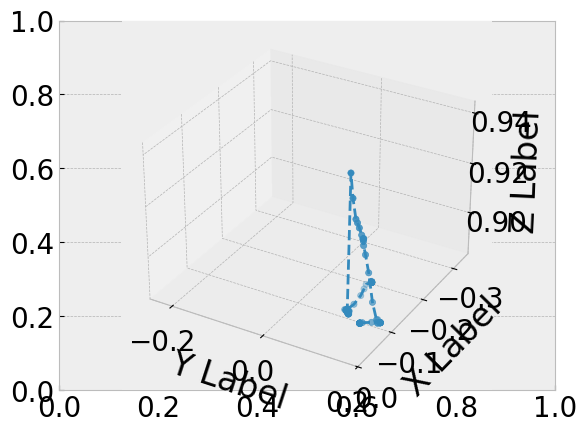

In [60]:
fig, ax = plt.subplots()
ax = fig.add_subplot(projection='3d')
ax.scatter(formatted['y'],formatted['x'],formatted['z'])
ax.plot(formatted['y'],formatted['x'],formatted['z'], '--')

ax.set_xlabel('Y Label')
ax.set_ylabel('X Label')
ax.set_zlabel('Z Label')

ax.set_xlim(-0.25, 0.2)
ax.set_ylim(0, -0.35)

# RQ1

### by success

In [61]:
successes = []
[successes.append([]) for _ in range(3)]
total = []
[total.append([]) for _ in range(3)]
passing_2 = []
[passing_2.append([]) for _ in range(3)]
passing_1 = []
[passing_1.append([]) for _ in range(3)]
failure = []
[failure.append([]) for _ in range(3)]

for idx, seed in enumerate(dfs):
    repeat1, repeat2, repeat3 = seed
    #repeat1 = repeat1.loc[repeat1["distractor"] == 3]
    #repeat2 = repeat2.loc[repeat2["distractor"] == 3]
    #repeat3 = repeat3.loc[repeat3["distractor"] == 3]
    # filter by success

    successes[idx] = pd.DataFrame([repeat1["success"],
                                   repeat2["success"],
                                   repeat3["success"]]).apply(lambda x: np.mean(x))

    total[idx] = [repeat1.loc[successes[idx] == 1],repeat2.loc[successes[idx] == 1],repeat3.loc[successes[idx] == 1]]
    passing_2[idx] = [repeat1.loc[successes[idx] == 2/3],repeat2.loc[successes[idx] == 2/3],repeat3.loc[successes[idx] == 2/3]]
    passing_1[idx] = [repeat1.loc[successes[idx] == 1/3],repeat2.loc[successes[idx] == 1/3],repeat3.loc[successes[idx] == 1/3]]
    failure[idx] = [repeat1.loc[successes[idx] == 0],repeat2.loc[successes[idx] == 0],repeat3.loc[successes[idx] == 0]]

In [62]:
print(sum([len(failure[0][0]),len(failure[1][0]),len(failure[2][0])]))
print(sum([len(passing_1[0][0]),len(passing_1[1][0]),len(passing_1[2][0])]))
print(sum([len(passing_2[0][0]),len(passing_2[1][0]),len(passing_2[2][0])]))
print(sum([len(total[0][0]),len(total[1][0]),len(total[2][0])]))

287
149
137
177


In [63]:
len(total[2][1])

59

#### Total

In [64]:
subset = total
last_step_coords = []
[last_step_coords.append([]) for _ in range(3)]
for idx, seed in enumerate(dfs):
    [last_step_coords[idx].append([]) for _ in range(3)]
    for i, repeat in enumerate(subset[idx]):
        repeat.apply(lambda x: last_step_coords[idx][i].append(np.linalg.norm(x["episode_coords"][x["episode_coords"].keys()[0]][119][:2])), axis=1)

laststepcoord_reshaped = [[[last_step_coords[seed][repeat][test] for repeat in range(3)] for test in range(len(last_step_coords[seed][0]))] for seed in range(3)]
total_std = [np.std(laststepcoord_reshaped[seed][test]) for seed in range(3) for test in range(len(laststepcoord_reshaped[seed]))]

In [65]:
len(total_std)

177

#### Passing 2

In [66]:
subset = passing_2
last_step_coords = []
[last_step_coords.append([]) for _ in range(3)]
for idx, seed in enumerate(dfs):
    [last_step_coords[idx].append([]) for _ in range(3)]
    for i, repeat in enumerate(subset[idx]):
        repeat.apply(lambda x: last_step_coords[idx][i].append(np.linalg.norm(x["episode_coords"][x["episode_coords"].keys()[0]][119][:2])), axis=1)

laststepcoord_reshaped = [[[last_step_coords[seed][repeat][test] for repeat in range(3)] for test in range(len(last_step_coords[seed][0]))] for seed in range(3)]
passing_2_std = [np.std(laststepcoord_reshaped[seed][test]) for seed in range(3) for test in range(len(laststepcoord_reshaped[seed]))]

#### Passing 1

In [67]:
subset = passing_1
last_step_coords = []
[last_step_coords.append([]) for _ in range(3)]
for idx, seed in enumerate(dfs):
    [last_step_coords[idx].append([]) for _ in range(3)]
    for i, repeat in enumerate(subset[idx]):
        repeat.apply(lambda x: last_step_coords[idx][i].append(np.linalg.norm(x["episode_coords"][x["episode_coords"].keys()[0]][119][:2])), axis=1)

laststepcoord_reshaped = [[[last_step_coords[seed][repeat][test] for repeat in range(3)] for test in range(len(last_step_coords[seed][0]))] for seed in range(3)]
passing_1_std = [np.std(laststepcoord_reshaped[seed][test]) for seed in range(3) for test in range(len(laststepcoord_reshaped[seed]))]

#### Failure

In [68]:
subset = failure
last_step_coords = []
[last_step_coords.append([]) for _ in range(3)]
for idx, seed in enumerate(dfs):
    [last_step_coords[idx].append([]) for _ in range(3)]
    for i, repeat in enumerate(subset[idx]):
        repeat.apply(lambda x: last_step_coords[idx][i].append(np.linalg.norm(x["episode_coords"][x["episode_coords"].keys()[0]][119][:2])), axis=1)

laststepcoord_reshaped = [[[last_step_coords[seed][repeat][test] for repeat in range(3)] for test in range(len(last_step_coords[seed][0]))] for seed in range(3)]
failure_std = [np.std(laststepcoord_reshaped[seed][test]) for seed in range(3) for test in range(len(laststepcoord_reshaped[seed]))]

In [69]:
failure_std

[np.float64(0.0),
 np.float64(0.0),
 np.float64(1.2682321603223395e-05),
 np.float64(0.055163240401062665),
 np.float64(0.0),
 np.float64(0.02337414041481148),
 np.float64(1.2290756658914105e-07),
 np.float64(0.0006735828780419057),
 np.float64(2.7755575615628914e-17),
 np.float64(0.05466696402973434),
 np.float64(0.0),
 np.float64(0.013612373955209383),
 np.float64(0.08062906316996145),
 np.float64(0.14738828620788222),
 np.float64(0.11488521609874223),
 np.float64(0.0008627437290019399),
 np.float64(0.06613785819536531),
 np.float64(0.029962915221176348),
 np.float64(3.881621973213188e-07),
 np.float64(0.029464163107339517),
 np.float64(0.038381387418604515),
 np.float64(0.003773106263720014),
 np.float64(0.057664498895492106),
 np.float64(0.0001504554352893406),
 np.float64(0.011573010901962253),
 np.float64(0.015546739508769792),
 np.float64(0.3243518137586949),
 np.float64(0.010940527069543047),
 np.float64(0.001795148985281681),
 np.float64(0.024140862378601392),
 np.float64(0.02

(array([239.,  27.,   8.,   1.,   2.,   1.,   2.,   1.,   2.,   1.,   1.,
          1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   1.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  , 1.05,
        1.1 , 1.15, 1.2 , 1.25, 1.3 , 1.35, 1.4 , 1.45, 1.5 , 1.55, 1.6 ,
        1.65, 1.7 , 1.75, 1.8 , 1.85, 1.9 , 1.95, 2.  , 2.05, 2.1 , 2.15,
        2.2 , 2.25, 2.3 , 2.35, 2.4 , 2.45, 2.5 , 2.55, 2.6 , 2.65, 2.7 ,
        2.75, 2.8 , 2.85, 2.9 , 2.95, 3.  , 3.05, 3.1 , 3.15, 3.2 , 3.25,
        3.3 , 3.35, 3.4 , 3.45, 3.5 ]),
 <BarContainer object of 70 artists>)

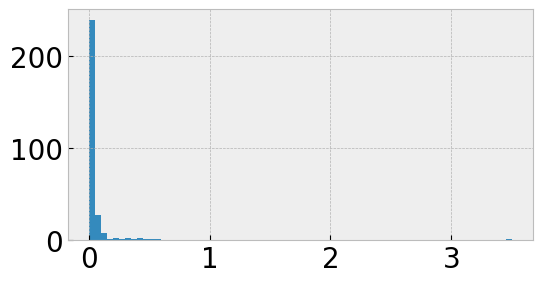

In [70]:
failure_std = [np.std(laststepcoord_reshaped[seed][test]) for seed in range(3) for test in range(len(laststepcoord_reshaped[seed]))]
fig, ax = plt.subplots(figsize=(6,3))
ax.hist(failure_std, bins=np.arange(0, np.max(failure_std)+0.05, 0.05))

In [71]:
np.std(laststepcoord_reshaped[0][8])

np.float64(2.7755575615628914e-17)

In [72]:
data_gr00t = total_std + passing_2_std + passing_1_std + failure_std
import pickle
with open(f'gr00t_fpd.pkl', 'wb') as f:  # Note: 'wb' for write binary
    pickle.dump(data_gr00t, f)

In [73]:
with open(f'spatial_fpd.pkl', 'rb') as f:
    data_spatial = pickle.load(f)

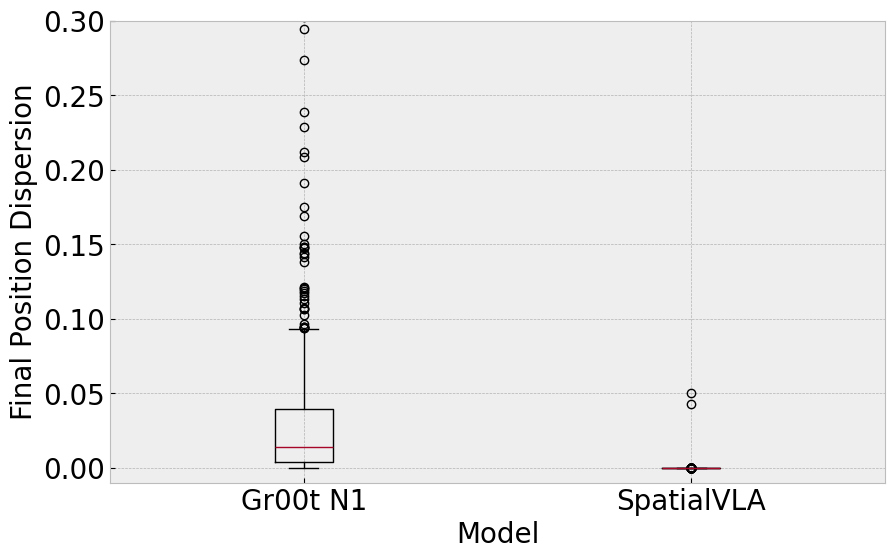

In [75]:
plt.rcParams.update({'font.size': 20})
fig, ax = plt.subplots(figsize=(10, 6))

#fig.suptitle("Gr00t N1: repartition of standard deviation of the source item at final step of simulation by average success rate", fontsize=14)
ax.boxplot([data_gr00t, data_spatial])
ax.set_ylim(-0.01, 0.3)
ax.set_xticklabels(["Gr00t N1", "SpatialVLA"])


ax.set_ylabel("Final Position Dispersion", fontsize=20)
ax.set_xlabel("Model", fontsize=20)

#ax.legend()
plt.savefig("img_short_paper/models_fpd_boxplot.pdf", format="pdf", bbox_inches='tight')

/tmp/ipykernel_10819/1124274010.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


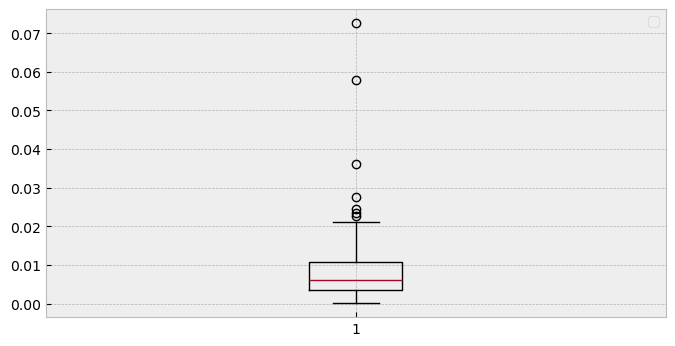

In [28]:
fig, ax = plt.subplots(figsize=(8,4))
data_multi = [total_std, passing_2_std, passing_1_std, failure_std]
#fig.suptitle("Gr00t N1: repartition of standard deviation of the source item at final step of simulation by average success rate", fontsize=14)
ax.boxplot(total_std)
ax.legend()

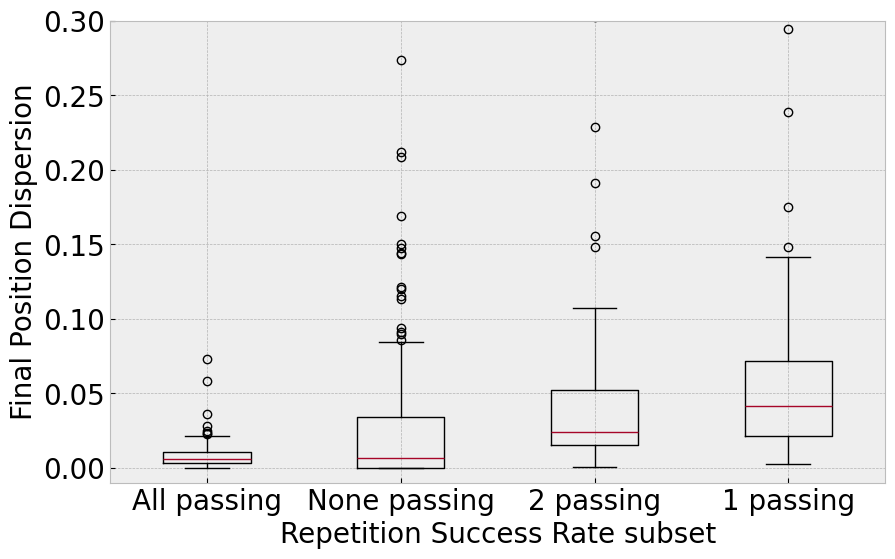

In [55]:
plt.rcParams.update({'font.size': 20})
fig, ax = plt.subplots(figsize=(10, 6))

data_multi = [total_std, failure_std, passing_2_std, passing_1_std]
#fig.suptitle("Gr00t N1: repartition of standard deviation of the source item at final step of simulation by average success rate", fontsize=14)
ax.boxplot(data_multi, 
        label=["All passing", "None passing", "2 passing", "1 passing",])
ax.set_ylim(-0.01, 0.3)
ax.set_xticklabels(["All passing", "None passing", "2 passing", "1 passing"])


ax.set_ylabel("Final Position Dispersion", fontsize=20)
ax.set_xlabel("Repetition Success Rate subset", fontsize=20)

#ax.legend()
plt.savefig("img_short_paper/gr00t_std_position_boxplot.pdf", format="pdf", bbox_inches='tight')

In [30]:
# from matplotlib.ticker import PercentFormatter

# fig, ax = plt.subplots(figsize=(8,4))
# plt.rcParams.update({'font.size': 14})
# data_multi = [total_std, passing_2_std, passing_1_std, failure_std]
# #fig.suptitle("Gr00t N1: repartition of standard deviation of the source item at final step of simulation by average success rate", fontsize=14)
# ax.hist(data_multi, 
#         weights=[
#             np.ones(len(total_std))/len(total_std),
#             np.ones(len(passing_2_std))/len(passing_2_std),
#             np.ones(len(passing_1_std))/len(passing_1_std),
#             np.ones(len(failure_std))/len(failure_std),], 
#         #bins=np.arange(0, 1, 0.1), 
#         bins=np.arange(0, 0.2, 0.02),
#         label=["All passing", "2 passing", "1 passing", "None passing"], 
#         color=["green", "blue", "orange", "red"],
#         align='left')
# ax.legend()
# ax.set_ylim(0,1)
# plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
# ax.set_ylabel("Percentage of tests", fontsize=16)
# ax.set_xlabel("Standard deviation of final position", fontsize=16)

# plt.savefig("img_short_paper/gr00t_proportion.pdf", format="pdf", bbox_inches='tight')

In [31]:
pd.DataFrame(total_std).loc[pd.DataFrame(total_std)[0] > 0.04]

,0
31,0.057874
157,0.072623


### Final pos, earliest_success

In [32]:
for i in range(3):
    for j in range(3):
        new_col = dfs[i][j].apply(lambda x: np.linalg.norm(x["episode_coords"][x["episode_coords"].keys()[0]][119][:2]), axis=1)
        dfs[i][j]['final_norm'] = new_col

In [33]:
earliest = []
[earliest.append([]) for _ in range(3)]

weights = []
[weights.append([]) for _ in range(3)]

norms = []
[norms.append([]) for _ in range(3)]

# first_30 = []
# [first_30.append([]) for _ in range(3)]
# second_60 = []
# [second_60.append([]) for _ in range(3)]
# third_90 = []
# [third_90.append([]) for _ in range(3)]
# last_120 = []
# [last_120.append([]) for _ in range(3)]

for idx, seed in enumerate(dfs):
    repeat1, repeat2, repeat3 = seed
    
    frame = pd.DataFrame([repeat1["earliest_success"],repeat2["earliest_success"],repeat3["earliest_success"]])
    final_norm = pd.DataFrame([repeat1["final_norm"],repeat2["final_norm"],repeat3["final_norm"]])
    # remove all fully failing
    kept = frame.T.loc[frame.apply(lambda x: np.sum(x) != 361)]
    kept.columns = ['a','b','c']
    weights[idx] = kept
    kept_norm = final_norm.T.loc[frame.apply(lambda x: np.sum(x) != 361)]
    kept_norm.columns = ['a','b','c']
    norms[idx] = kept_norm
    earliest[idx] = kept.apply(lambda x: np.average(x), axis=1)

    #weights=[1 if (e > -1 and e < 120) else 0 for e in x]

In [34]:
earliest_norms = []
[earliest_norms.append([]) for _ in range(3)]
for idx in range(3):
    earliest_norms[idx] = pd.concat([weights[idx], norms[idx], earliest[idx]], axis=1)
    earliest_norms[idx].columns = ['sa', 'sb', 'sc', 'na', 'nb', 'nc', 'avg_step']
    earliest_norms[idx]['std'] = earliest_norms[idx].apply(lambda x: np.std([x['na'],x['nb'],x['nc']]),axis=1)

In [35]:
thirty = pd.concat([earliest_norms[i].loc[earliest_norms[i]['avg_step'] <= 30][['avg_step', 'std']] for i in range(3)], ignore_index=True)
sixty = pd.concat([earliest_norms[i].loc[(earliest_norms[i]['avg_step'] > 30) & (earliest_norms[i]['avg_step'] <= 60)][['avg_step', 'std']] for i in range(3)], ignore_index=True)
ninety = pd.concat([earliest_norms[i].loc[(earliest_norms[i]['avg_step'] > 60) & (earliest_norms[i]['avg_step'] <= 90)][['avg_step', 'std']] for i in range(3)], ignore_index=True)
hundred_nineteen = pd.concat([earliest_norms[i].loc[(earliest_norms[i]['avg_step'] > 90) & (earliest_norms[i]['avg_step'] < 120)][['avg_step', 'std']] for i in range(3)], ignore_index=True)
hundred_twenty = pd.concat([earliest_norms[i].loc[earliest_norms[i]['avg_step'] == 120][['avg_step', 'std']] for i in range(3)], ignore_index=True)


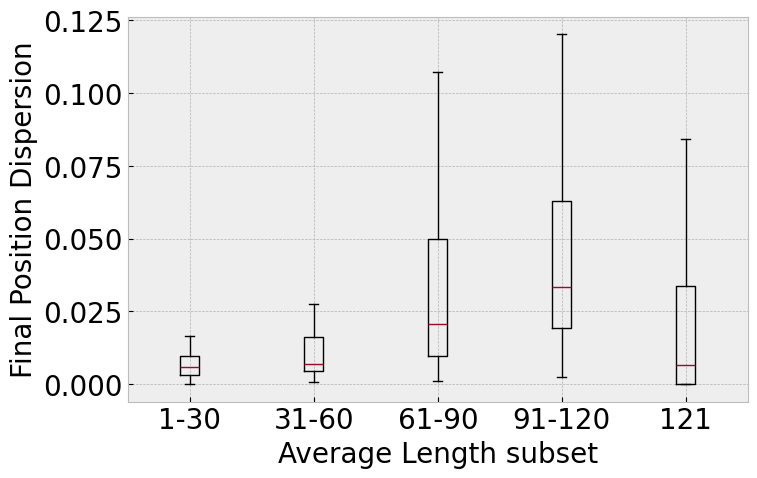

In [56]:
plt.rcParams.update({'font.size': 20})
fig, ax = plt.subplots(figsize=(8,5))
datasets = [(thirty['std'], "1-30"), (sixty['std'], "31-60"), (ninety['std'], "61-90"), (hundred_nineteen['std'], "91-120"), (hundred_twenty['std'], '121')]
for idx, dataset in enumerate(datasets):
    data = dataset[0]
    ax.boxplot(data, positions=[idx], showfliers=False)

#ax.set_ylim(0, 120)
ax.set_xticklabels([datasets[0][1], datasets[1][1], datasets[2][1], datasets[3][1], datasets[4][1]])


ax.set_ylabel("Final Position Dispersion", fontsize=20)
ax.set_xlabel("Average Length subset", fontsize=20)

plt.savefig("img_short_paper/gr00t_FPD_by_avglength.pdf", format="pdf", bbox_inches='tight')

### Earliest success

In [37]:
# from operator import countOf

# every = []
# [every.append([]) for _ in range(3)]
# antievery = []
# [antievery.append([]) for _ in range(3)]

# all_passing = []
# [all_passing.append([]) for _ in range(3)]
# two_passing = []
# [two_passing.append([]) for _ in range(3)]
# one_passing = []
# [one_passing.append([]) for _ in range(3)]

# for idx, seed in enumerate(dfs):
#     repeat1, repeat2, repeat3 = seed
    
#     # repeat1 = repeat1.loc[repeat1['success'] == True]
#     # repeat2 = repeat2.loc[repeat2['success'] == True]
#     # repeat3 = repeat3.loc[repeat3['success'] == True]
#     frame = pd.DataFrame([repeat1["earliest_success"],repeat2["earliest_success"],repeat3["earliest_success"]])
#     # remove all fully failing
#     unkept = frame.T.loc[frame.apply(lambda x: np.sum(x) == 360)].T
#     kept = frame.T.loc[frame.apply(lambda x: np.sum(x) != 360)].T
#     f_all_passing = frame.T.loc[frame.apply(lambda x: countOf(x, 120) == 0)].T
#     f_two_passing = frame.T.loc[frame.apply(lambda x: countOf(x, 120) == 1)].T
#     f_one_passing = frame.T.loc[frame.apply(lambda x: countOf(x, 120) == 2)].T
    

#     antievery[idx] = unkept.apply(lambda x: np.average(x))
#     every[idx] = kept.apply(lambda x: np.average(x, weights=[1 if (e > -1 and e < 120) else 0 for e in x]))

#     all_passing[idx] = f_all_passing.apply(lambda x: np.average(x, weights=[1 if (e > -1 and e < 120) else 0 for e in x]))
#     two_passing[idx] = f_two_passing.apply(lambda x: np.average(x, weights=[1 if (e > -1 and e < 120) else 0 for e in x]))
#     one_passing[idx] = f_one_passing.apply(lambda x: np.average(x, weights=[1 if (e > -1 and e < 120) else 0 for e in x]))

In [38]:
# fig, ax = plt.subplots(figsize=(8,5))
# datasets = [(all_passing, "All passing"), (two_passing, "Two passing"), (one_passing, "One passing")]
# for idx, dataset in enumerate(datasets):
#     data = pd.concat(dataset[0])
#     #ax.set_title(dataset[1])
#     ax.boxplot(data, positions=[idx])

# ax.set_ylim(0, 120)
# ax.set_xticklabels([datasets[0][1], datasets[1][1], datasets[2][1]])
# ax.set_ylabel("steps")

# plt.rcParams.update({'font.size': 16})
# ax.set_ylabel("Step of earliest success", fontsize=16)
# ax.set_xlabel("Subset", fontsize=20)

# plt.savefig("img_short_paper/gr00t_step_by_passing.pdf", format="pdf", bbox_inches='tight')

# RQ2

In [39]:
nb_test = 50
values = []
[values.append([]) for _ in range(nb_test)]
for test in range(nb_test):
    for repeat in dfs[0]:
        repetition = repeat.loc[test]
        step_coords = repetition['episode_coords']
        target = step_coords.keys()[0]
        values[test].append(step_coords[target])

In [40]:
print(repeat.loc[0]['x1'])
print(repeat.loc[0]['y1'])

-0.07800000000000001
0.15000000000000002


In [41]:
np.linalg.norm([repeat.loc[0]['x1'], repeat.loc[0]['y1']])

np.float64(0.16906803364326448)

In [42]:
p = 2
(abs(repeat.loc[0]['x1']) ** 2 + abs(repeat.loc[0]['y1']) ** 2) ** (1/2)

np.float64(0.16906803364326448)

In [43]:
linalg = [[[np.linalg.norm(coords) for coords in repeat] for repeat in test] for test in values]
standev_entire = [np.std(test) for test in linalg] # std for each test
standev_step = [ [np.std([test[0][step],test[1][step],test[2][step]]) for step in range(120)] for test in linalg] # std for each step

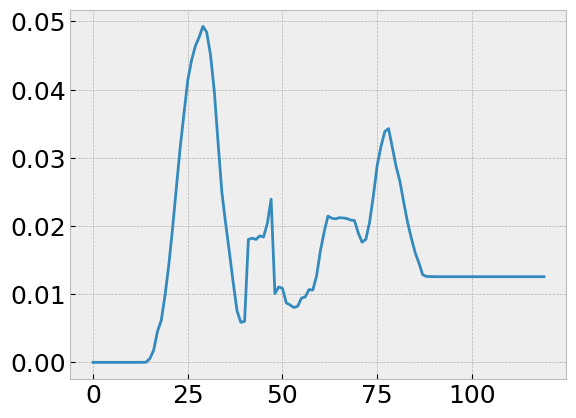

In [44]:
fig, ax = plt.subplots()
ax.plot(standev_step[0])

In [45]:
by_step = [ [standev_step[test][step] for test in range(50)] for step in range(120)] # flip the data

In [46]:
fused = [[dfs[i][j]['episode_coords'] for j in range(3)] for i in range(3)]
#fused = pd.concat(fused, ignore_index=True)
values = [[fused[i][j].apply(lambda x: x[x.keys()[0]].apply(lambda y: np.linalg.norm(y))).T for j in range(len(fused[i]))] for i in range(len(fused))]
#values = fused.apply(lambda x: x[x.keys()[0]])

In [47]:
data = []
[data.append([]) for _ in range(3)]
for idx, seed in enumerate(values):
    repeat1, repeat2, repeat3 = seed
    frame = [[np.std([repeat1.loc[i][j], repeat2.loc[i][j], repeat3.loc[i][j]]) for j in range(250)] for i in range(120)]
    data[idx] = frame

In [48]:
len(data[0][0])
final = [data[0][i] + data[1][i] + data[2][i] for i in range(120)]

In [49]:
len(final[0])

750

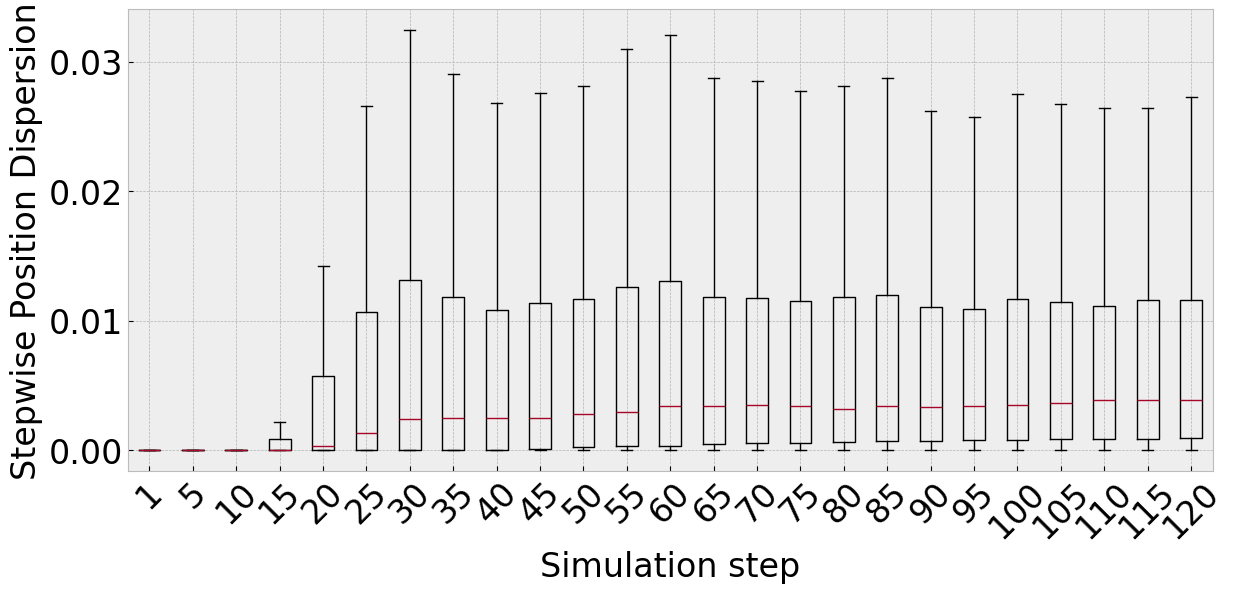

In [57]:
plt.rcParams.update({'font.size': 24})
fig, ax = plt.subplots(figsize=(14,6))
data = [final[0]] + final[4::5]
ax.boxplot(data, showfliers=False)
ticks = ax.get_xticks()
labels = [1] + [x+1 for x in range(4, 120, 5)]

#ax.set_xticks(ticks[::10])
ax.set_xticklabels(labels)
plt.xticks(rotation=45, ha="center")


ax.set_ylabel("Stepwise Position Dispersion", fontsize=24)
ax.set_xlabel("Simulation step", fontsize=24)

plt.savefig("img_short_paper/gr00t_step_std.pdf", format="pdf", bbox_inches='tight')